## Load Model and Test Data
Import, load the models and generate risk probabilities

In [13]:
import re
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# Load the trained model and test data
model = joblib.load('../models/lgbm_readmission_model.pkl')
X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv').squeeze()

# Apply same column name cleanup in train.py
X_test.columns = [re.sub(r'[^A-Za-z0-9_]+', '_', col) for col in X_test.columns]

# Generate risk probabilities
y_pred_proba = model.predict_proba(X_test)[:, 1]
print(f"Loaded {len(X_test)} test patients. Max risk score: {y_pred_proba.max():.3f}")

Loaded 19810 test patients. Max risk score: 0.850


## Calculate SHAP values

In [14]:
# Sample 2,000 patients for fast SHAP visualization
X_sample = X_test.sample(n=2000, random_state=42)

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_sample)

# Isolate SHAP values
# Isolate for Class 1 (High Risk <30) if the SHAP values are 3D
if len(shap_values.shape) == 3:
    shap_values_class1 = shap_values[:, :, 1]
else:
    shap_values_class1 = shap_values

## Global Interpretability
Beeswarm Summary Plot

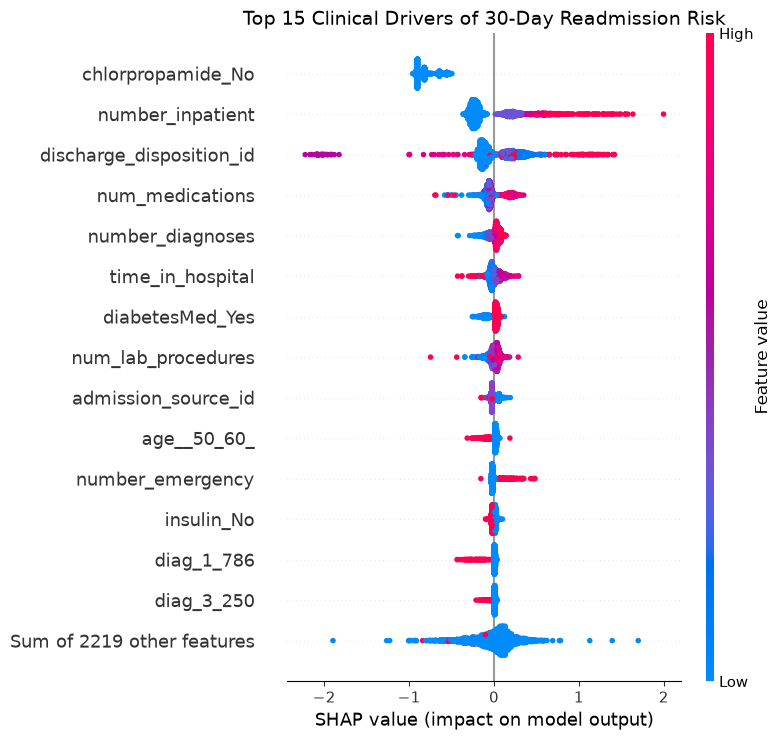

In [15]:
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values_class1, max_display=15, show=False)
plt.title("Top 15 Clinical Drivers of 30-Day Readmission Risk", fontsize=14)
plt.tight_layout()
plt.savefig('../reports/shap_global_summary.png', dpi=300, bbox_inches='tight')
plt.show()

## Local Interpretability

Single Patient Waterfall Plot

Inspecting Patient Index: 15219
Predicted Readmission Risk: 78.0%


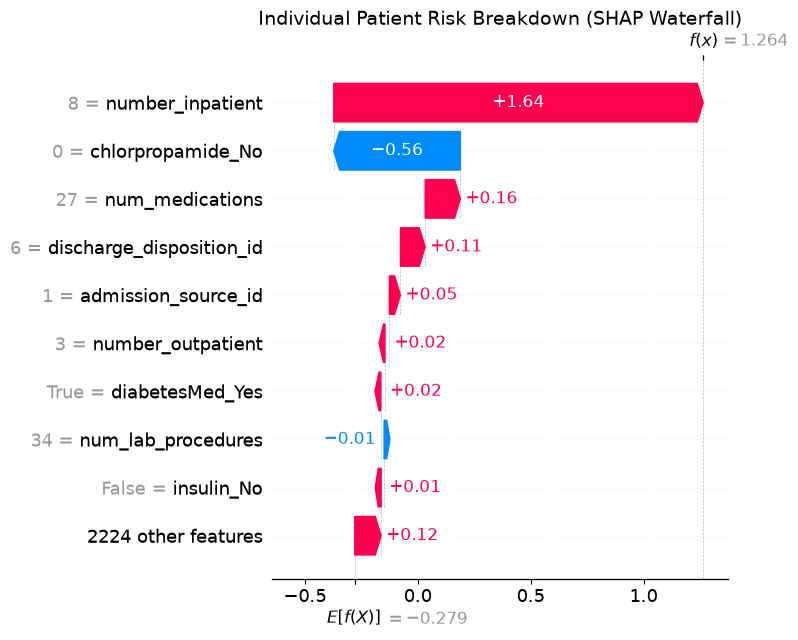

In [16]:
# Find the highest-risk patient inside our 2,000-patient sample
sample_probs = model.predict_proba(X_sample)[:, 1]
top_risk_idx = np.argmax(sample_probs)

print(f"Inspecting Patient Index: {X_sample.index[top_risk_idx]}")
print(f"Predicted Readmission Risk: {sample_probs[top_risk_idx]:.1%}")

plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values_class1[top_risk_idx], max_display=10, show=False)
plt.title("Individual Patient Risk Breakdown (SHAP Waterfall)", fontsize=14)
plt.tight_layout()
plt.savefig('../reports/shap_patient_waterfall.png', dpi=300, bbox_inches='tight')
plt.show()

## Export Scored Dataset

In [17]:
# Build a clean export table for Tableau
tableau_df = pd.DataFrame({
    'patient_index': X_test.index,
    'time_in_hospital': X_test['time_in_hospital'],
    'num_lab_procedures': X_test['num_lab_procedures'],
    'num_procedures': X_test['num_procedures'],
    'num_medications': X_test['num_medications'],
    'number_outpatient': X_test['number_outpatient'],
    'number_emergency': X_test['number_emergency'],
    'number_inpatient': X_test['number_inpatient'],
    'number_diagnoses': X_test['number_diagnoses'],
    'actual_readmitted': y_test.values,
    'risk_score': y_pred_proba
})

# Assign risk tiers 
def assign_risk_tier(prob):
    if prob >= 0.35:
        return 'High Risk (>=35%)'
    elif prob >= 0.25:
        return 'Medium Risk (25-34%)'
    else:
        return 'Low Risk (<25%)'

tableau_df['risk_tier'] = tableau_df['risk_score'].apply(assign_risk_tier)
tableau_df['flagged_for_outreach'] = (tableau_df['risk_score'] >= 0.25).astype(int)

tableau_df.to_csv('../data/processed/tableau_readmission_data.csv', index=False)
print("Exported ../data/processed/tableau_readmission_data.csv successfully!")
print(tableau_df['risk_tier'].value_counts())

Exported ../data/processed/tableau_readmission_data.csv successfully!
risk_tier
Low Risk (<25%)         10319
Medium Risk (25-34%)     4997
High Risk (>=35%)        4494
Name: count, dtype: int64
